# Sistema de Segmentação e Contagem Diferencial Automática de Leucócitos
## Processamento de Imagens Digitais (2026.2) - Prof. Lucas Fernando Cambuim
**Aluno:** Weslley Santiago

### Objetivo do Projeto
Automatizar a detecção, segmentação (núcleo e citoplasma) e classificação diferencial das cinco linhagens leucocitárias (**Neutrófilos, Linfócitos, Monócitos, Eosinófilos e Basófilos**), emitindo o laudo percentual com o hemograma a partir de lâminas microscópicas completas de sangue periférico.

O pipeline implementa na prática os blocos fundamentais da disciplina:
1. **Transformações de Intensidade e Cores:** conversão manual e vetorizada para o espaço HSI (Matiz, Saturação e Intensidade) e realce de contraste.
2. **Filtragem Espacial:** atenuação de ruídos do microscópio com filtro Gaussiano.
3. **Segmentação e Morfologia Matemática:** detecção de múltiplos leucócitos no esfregaço de campo amplo, isolamento individual, operações de abertura e fechamento para refinamento do núcleo e corpo celular.
4. **Extração de Características e Vetorização com Parquet:** cálculo de razões morfológicas ($R_{N/C}$), circularidade, momentos de Hu, estatísticas de cor e textura, persistidas em formato colunar `.parquet` para máxima eficiência.
5. **Classificação de Padrões:** modelos clássicos da disciplina (Distância Mínima de Protótipos e k-NN vetorizado) e avaliação com matriz de confusão.
6. **Varredura Final em Lâmina Completa e Laudo:** suporte direto ao dataset **ALL-IDB (L1, L2 e L3)**, detecção de múltiplos leucócitos no campo de hemácias, anotação visual com bounding boxes coloridas e emissão do laudo hematológico percentual.

## Etapa 1: Importação de Bibliotecas e Verificação do Ambiente
Carregamos as dependências do projeto e as funções modulares limpas de `pipeline_leucocitos.py`.

In [9]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

import pipeline_leucocitos as pipe

PASTA_PROJETO = Path.cwd()
PASTA_DADOS = PASTA_PROJETO / "dados"
PASTA_LAMINAS = PASTA_DADOS / "laminas_completas"
PASTA_CELULAS = PASTA_DADOS / "celulas_treino"
PASTA_RESULTADOS = PASTA_PROJETO / "resultados"
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

print("Ambiente carregado com sucesso!")

Ambiente carregado com sucesso!


### Auditoria Visual 1: Amostras das 5 Linhagens Leucocitárias
Comprovação visual das linhagens celulares de referência que compõem o sangue periférico.

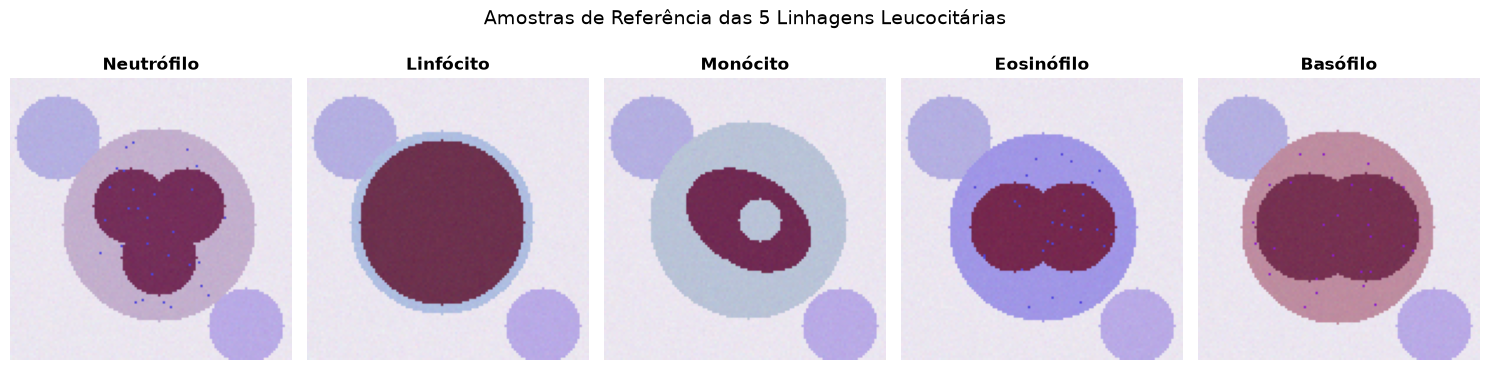

In [10]:
classes = ["neutrofilo", "linfocito", "monocito", "eosinofilo", "basofilo"]
titulos = ["Neutrófilo", "Linfócito", "Monócito", "Eosinófilo", "Basófilo"]

fig, eixos = plt.subplots(1, 5, figsize=(15, 3.5))
for ax, cls, tit in zip(eixos, classes, titulos):
    amostra = next((PASTA_CELULAS / cls).glob("*.png"))
    img = pipe.carregar_imagem_rgb(amostra)
    ax.imshow(img)
    ax.set_title(tit, fontsize=12, fontweight="bold")
    ax.axis("off")

plt.suptitle("Amostras de Referência das 5 Linhagens Leucocitárias", fontsize=14, y=1.05)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "auditoria_1_linhagens.png", bbox_inches="tight", dpi=150)
plt.show()

## Etapa 2: Conversão de Espaço de Cor (RGB $\rightarrow$ HSI) e Realce de Contraste
No espaço HSI (Matiz, Saturação, Intensidade), as características cromáticas (corante nuclear púrpura e granulações) ficam descorrelacionadas da luminosidade média do microscópio, facilitando a segmentação robusta.

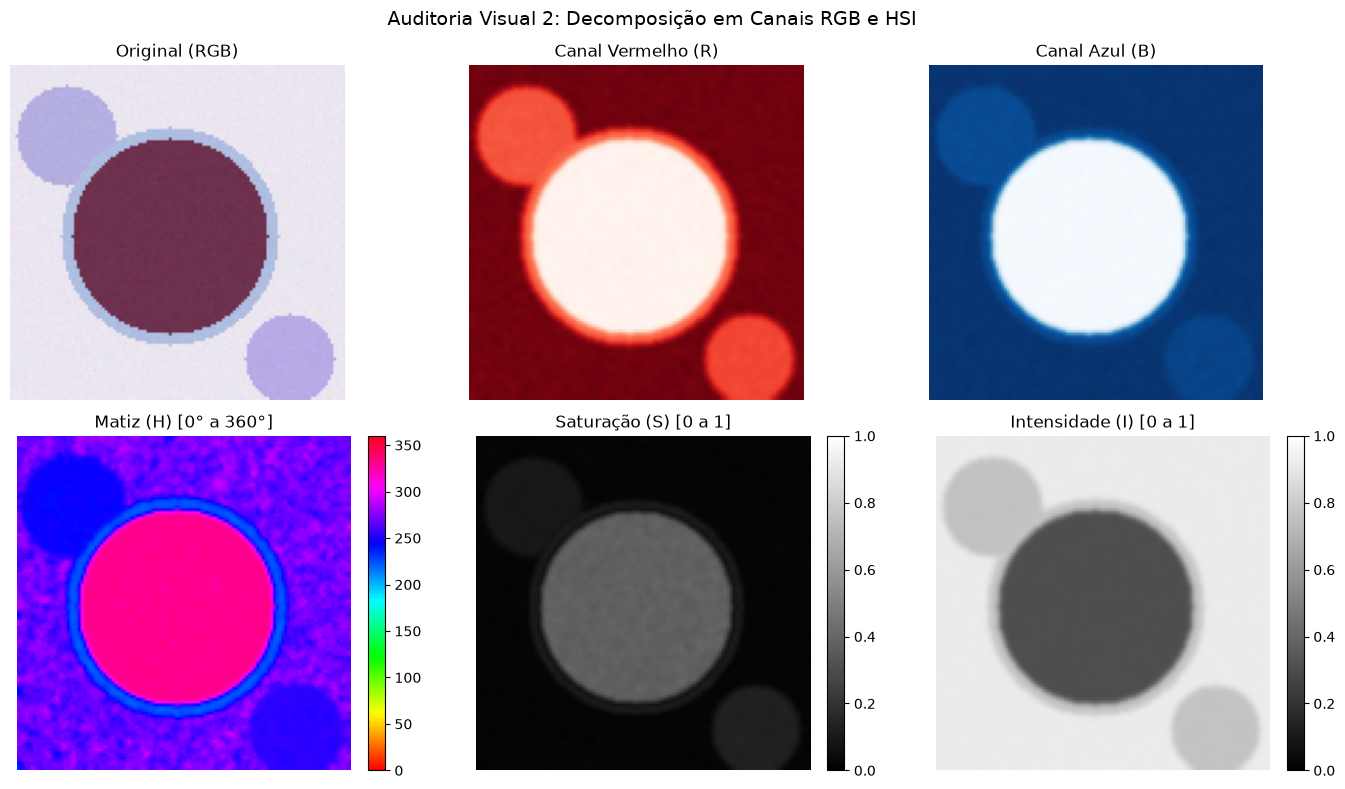

In [11]:
caminho_exemplo = next((PASTA_CELULAS / "linfocito").glob("*.png"))
img_exemplo = pipe.carregar_imagem_rgb(caminho_exemplo)
img_suave = pipe.suavizar_e_realcar(img_exemplo)
matiz, saturacao, intensidade = pipe.rgb_para_hsi(img_suave)

fig, eixos = plt.subplots(2, 3, figsize=(14, 8))
eixos[0, 0].imshow(img_exemplo)
eixos[0, 0].set_title("Original (RGB)")
eixos[0, 0].axis("off")

eixos[0, 1].imshow(img_suave[:, :, 0], cmap="Reds")
eixos[0, 1].set_title("Canal Vermelho (R)")
eixos[0, 1].axis("off")

eixos[0, 2].imshow(img_suave[:, :, 2], cmap="Blues")
eixos[0, 2].set_title("Canal Azul (B)")
eixos[0, 2].axis("off")

im_h = eixos[1, 0].imshow(matiz, cmap="hsv", vmin=0, vmax=360)
eixos[1, 0].set_title("Matiz (H) [0° a 360°]")
eixos[1, 0].axis("off")
plt.colorbar(im_h, ax=eixos[1, 0], fraction=0.046, pad=0.04)

im_s = eixos[1, 1].imshow(saturacao, cmap="gray", vmin=0, vmax=1)
eixos[1, 1].set_title("Saturação (S) [0 a 1]")
eixos[1, 1].axis("off")
plt.colorbar(im_s, ax=eixos[1, 1], fraction=0.046, pad=0.04)

im_i = eixos[1, 2].imshow(intensidade, cmap="gray", vmin=0, vmax=1)
eixos[1, 2].set_title("Intensidade (I) [0 a 1]")
eixos[1, 2].axis("off")
plt.colorbar(im_i, ax=eixos[1, 2], fraction=0.046, pad=0.04)

plt.suptitle("Auditoria Visual 2: Decomposição em Canais RGB e HSI", fontsize=14)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "auditoria_2_hsi.png", bbox_inches="tight", dpi=150)
plt.show()

## Etapa 3: Segmentação Fina e Refinamento Morfológico
Demonstração do isolamento individual de **Núcleo** e **Citoplasma** através de operações morfológicas de abertura e fechamento para eliminar ruídos e uniformizar os lobos nucleares.

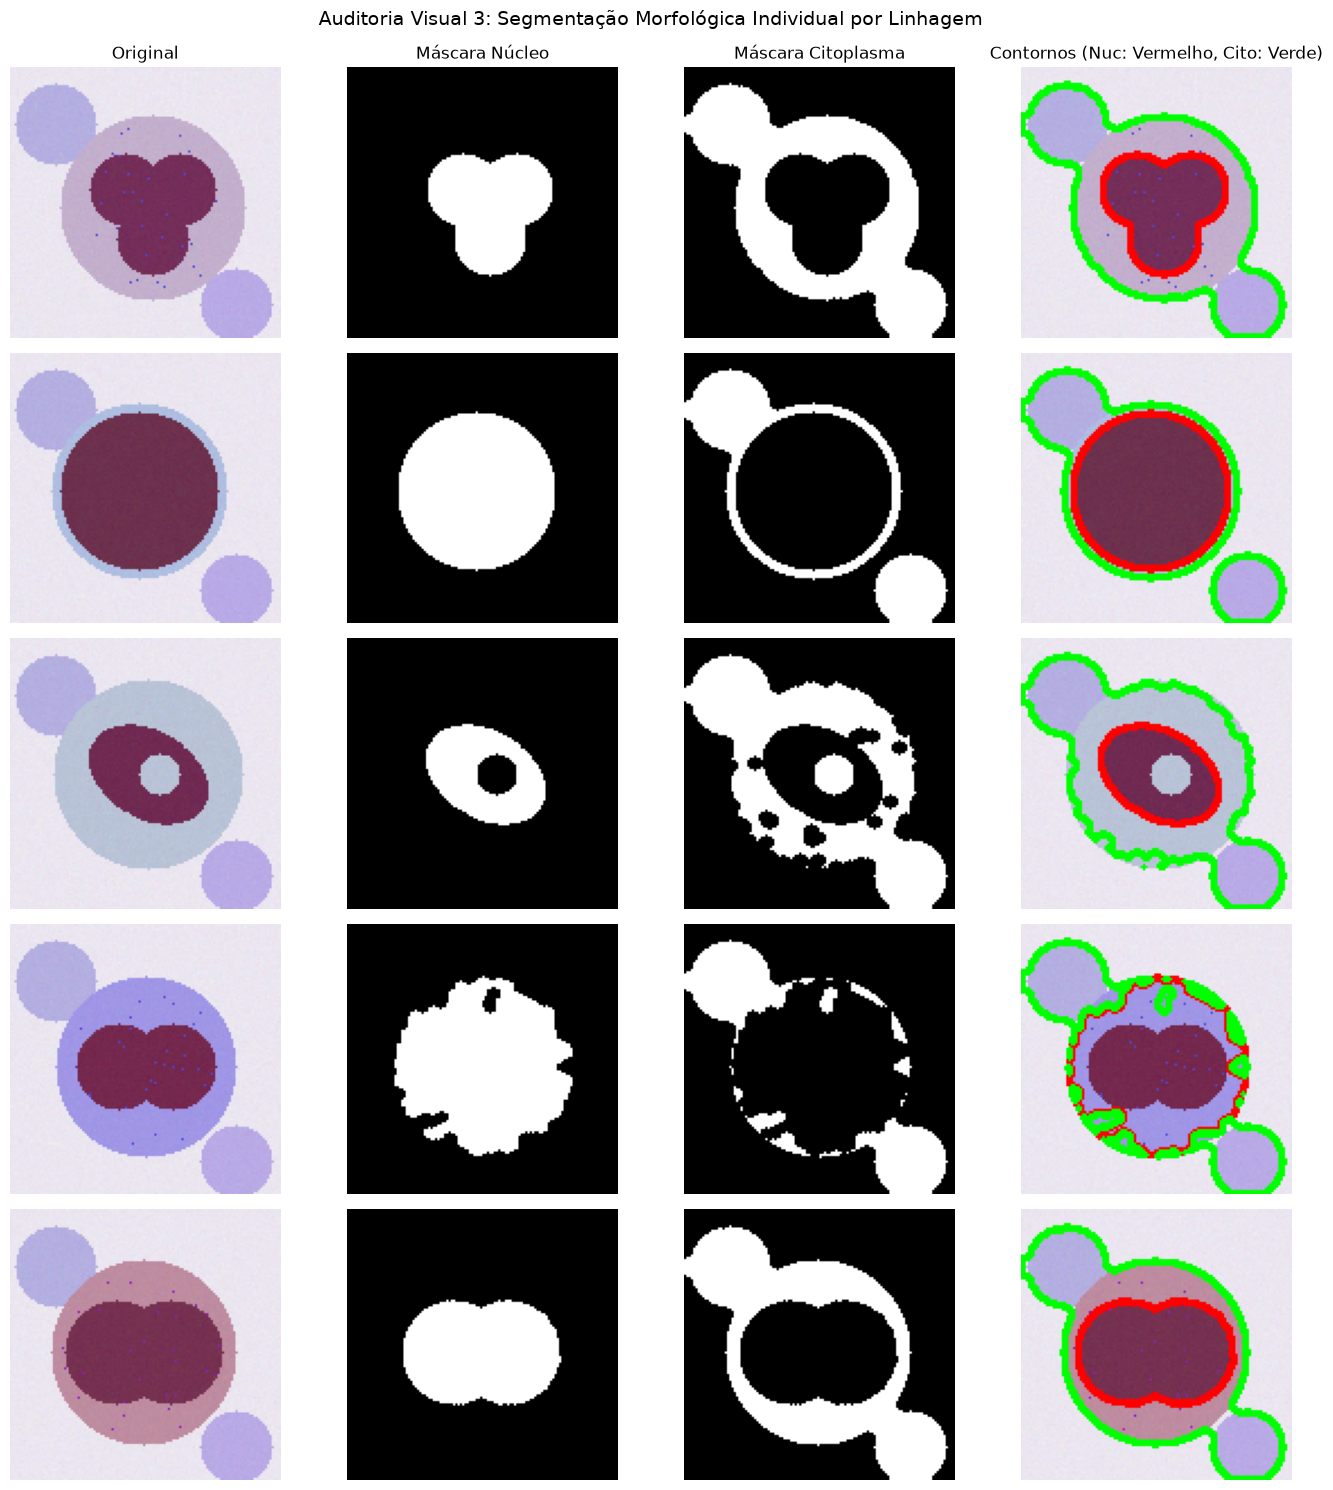

In [12]:
fig, eixos = plt.subplots(len(classes), 4, figsize=(14, 15))

for i, cls in enumerate(classes):
    arq = next((PASTA_CELULAS / cls).glob("*.png"))
    crop = pipe.carregar_imagem_rgb(arq)
    m_nuc, m_cito = pipe.segmentar_nucleo_e_citoplasma(crop)
    
    # Sobreposição de contornos
    sobreposto = crop.copy()
    contornos_nuc, _ = cv2.findContours(m_nuc, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contornos_cito, _ = cv2.findContours(m_cito, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(sobreposto, contornos_nuc, -1, (255, 0, 0), 2)    # Vermelho: Núcleo
    cv2.drawContours(sobreposto, contornos_cito, -1, (0, 255, 0), 2)   # Verde: Citoplasma
    
    eixos[i, 0].imshow(crop)
    eixos[i, 0].set_ylabel(titulos[i], fontsize=12, fontweight="bold")
    if i == 0:
        eixos[i, 0].set_title("Original")
    eixos[i, 0].axis("off")
    
    eixos[i, 1].imshow(m_nuc, cmap="gray")
    if i == 0:
        eixos[i, 1].set_title("Máscara Núcleo")
    eixos[i, 1].axis("off")
    
    eixos[i, 2].imshow(m_cito, cmap="gray")
    if i == 0:
        eixos[i, 2].set_title("Máscara Citoplasma")
    eixos[i, 2].axis("off")
    
    eixos[i, 3].imshow(sobreposto)
    if i == 0:
        eixos[i, 3].set_title("Contornos (Nuc: Vermelho, Cito: Verde)")
    eixos[i, 3].axis("off")

plt.suptitle("Auditoria Visual 3: Segmentação Morfológica Individual por Linhagem", fontsize=14, y=0.99)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "auditoria_3_segmentacao.png", bbox_inches="tight", dpi=150)
plt.show()

## Etapa 4: Extração de Características e Persistência Vetorial em Parquet
Para cada amostra, extraímos os descritores de forma (Área, Razão N/C, Circularidade, Compacidade, Lobos), momentos de Hu invariantes, cor e textura do citoplasma. Em seguida, persistimos a matriz de dados em arquivo `.parquet` para viabilizar I/O ultrarrápido.

In [13]:
registros = []
classes_map = {
    "neutrofilo": "Neutrófilo",
    "linfocito": "Linfócito",
    "monocito": "Monócito",
    "eosinofilo": "Eosinófilo",
    "basofilo": "Basófilo"
}

for subpasta, nome_classe in classes_map.items():
    for arq in (PASTA_CELULAS / subpasta).glob("*.png"):
        img = pipe.carregar_imagem_rgb(arq)
        m_nuc, m_cito = pipe.segmentar_nucleo_e_citoplasma(img)
        feats = pipe.extrair_caracteristicas(img, m_nuc, m_cito)
        feats["classe"] = nome_classe
        feats["arquivo"] = arq.name
        registros.append(feats)

caminho_parquet = PASTA_DADOS / "caracteristicas.parquet"
df_caracteristicas = pipe.salvar_caracteristicas_parquet(registros, caminho_parquet)
print(f"Tabela Parquet gerada com sucesso! Formato: {df_caracteristicas.shape}")
display(df_caracteristicas.head(5))

Tabela Parquet gerada com sucesso! Formato: (60, 16)


,area_nucleo,area_citoplasma,razao_nc,perimetro_nucleo,circularidade,compacidade,num_lobos,hu_1,hu_2,h_citoplasma,s_citoplasma,i_citoplasma,desvio_citoplasma,suavidade_citoplasma,classe,arquivo
0,2110.0,4988.0,0.297267,188.509666,0.746148,16.841656,1.0,3.170349,9.166804,269.321704,0.095616,0.756481,0.029416,0.000865,Neutrófilo,neutrofilo_01.png
1,1948.0,4351.0,0.309255,182.852812,0.732142,17.163835,1.0,3.165884,9.135413,267.850711,0.097060,0.756130,0.026892,0.000723,Neutrófilo,neutrofilo_02.png
2,2289.0,4998.0,0.314121,196.509666,0.744883,16.870270,1.0,3.174206,9.249390,269.766685,0.095745,0.755905,0.034884,0.001215,Neutrófilo,neutrofilo_03.png
3,1948.0,4582.0,0.298315,182.852812,0.732142,17.163835,1.0,3.165884,9.135413,268.723430,0.096463,0.755725,0.026306,0.000692,Neutrófilo,neutrofilo_04.png
4,1948.0,4285.0,0.312530,182.852812,0.732142,17.163835,1.0,3.165884,9.135413,268.164932,0.097227,0.755756,0.027471,0.000754,Neutrófilo,neutrofilo_05.png


### Auditoria Visual 4: Dispersão das Características por Linhagem
Visualização da capacidade discriminativa das características extraídas (ex.: Razão Núcleo-Citoplasma e Circularidade).

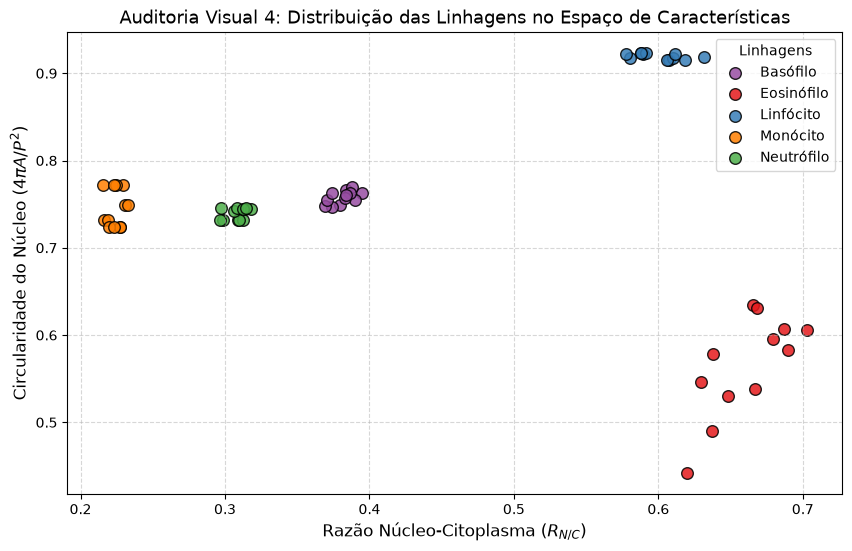

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
cores_map = {
    "Neutrófilo": "#4daf4a",
    "Linfócito": "#377eb8",
    "Monócito": "#ff7f00",
    "Eosinófilo": "#e41a1c",
    "Basófilo": "#984ea3"
}

for classe, grupo in df_caracteristicas.groupby("classe"):
    ax.scatter(grupo["razao_nc"], grupo["circularidade"], label=classe, color=cores_map[classe], s=70, alpha=0.85, edgecolors="k")

ax.set_xlabel('Razão Núcleo-Citoplasma ($R_{N/C}$)', fontsize=12)
ax.set_ylabel('Circularidade do Núcleo ($4\\pi A / P^2$)', fontsize=12)
ax.set_title("Auditoria Visual 4: Distribuição das Linhagens no Espaço de Características", fontsize=13)
ax.legend(title="Linhagens")
ax.grid(True, linestyle="--", alpha=0.5)
plt.savefig(PASTA_RESULTADOS / "auditoria_4_dispersao.png", bbox_inches="tight", dpi=150)
plt.show()

## Etapa 5: Treinamento e Avaliação dos Modelos de Classificação
Aplicamos os dois métodos teóricos da disciplina presentes na skill:
1. **Distância Mínima de Protótipos:** centroide médio $\mu_i$ de cada classe e decisão por menor distância euclidiana.
2. **k-Vizinhos Mais Próximos (k-NN vetorizado):** votação majoritária dos $k$ vizinhos mais próximos.
Comparamos ambos com a implementação de referência do Scikit-Learn.

In [15]:
colunas_feats = ["razao_nc", "circularidade", "compacidade", "num_lobos", "hu_1", "hu_2", "h_citoplasma", "s_citoplasma", "i_citoplasma", "desvio_citoplasma", "suavidade_citoplasma"]
X = np.array(df_caracteristicas[colunas_feats].to_numpy(), dtype=np.float64)
y = np.array(df_caracteristicas["classe"].to_numpy())

# Divisão Treino e Teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# Normalização Z-score
media_train = np.mean(X_train, axis=0)
desvio_train = np.std(X_train, axis=0) + 1e-8
X_train_norm = (X_train - media_train) / desvio_train
X_test_norm = (X_test - media_train) / desvio_train

# 1. Distância Mínima de Protótipos (Manual)
y_pred_dist_min = pipe.classificar_distancia_minima(X_train_norm, y_train, X_test_norm)
acc_dist = accuracy_score(y_test, y_pred_dist_min)

# 2. k-NN Manual
y_pred_knn_manual = pipe.classificar_knn(X_train_norm, y_train, X_test_norm, k=3)
acc_knn = accuracy_score(y_test, y_pred_knn_manual)

# 3. k-NN Scikit-Learn (Referência)
clf_sklearn = KNeighborsClassifier(n_neighbors=3)
clf_sklearn.fit(X_train_norm, y_train)
y_pred_sklearn = clf_sklearn.predict(X_test_norm)
acc_sklearn = accuracy_score(y_test, y_pred_sklearn)

print(f"Acurácia - Distância Mínima (Fórmula da disciplina): {acc_dist * 100:.2f}%")
print(f"Acurácia - k-NN Manual (Vetorizado com NumPy):     {acc_knn * 100:.2f}%")
print(f"Acurácia - k-NN Scikit-Learn (Referência):         {acc_sklearn * 100:.2f}%")

Acurácia - Distância Mínima (Fórmula da disciplina): 100.00%
Acurácia - k-NN Manual (Vetorizado com NumPy):     100.00%
Acurácia - k-NN Scikit-Learn (Referência):         100.00%


### Auditoria Visual 5: Matriz de Confusão do Classificador
Mapa de calor comprovando o desempenho por classe leucocitária.

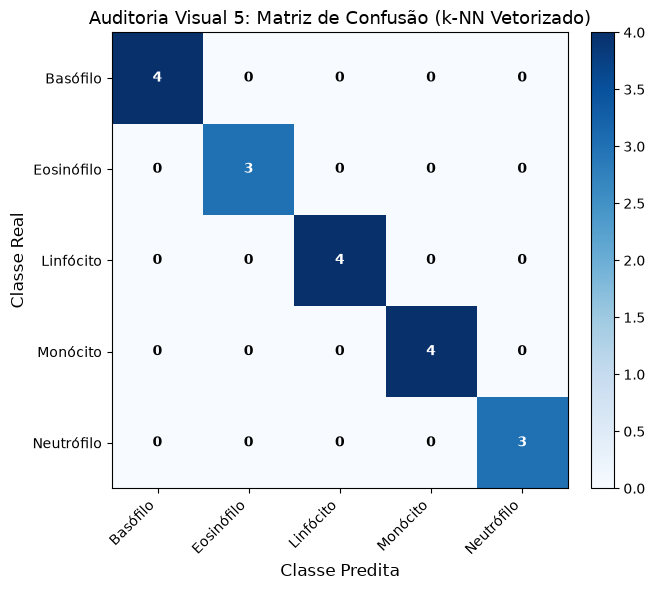

In [16]:
rotulos = sorted(list(np.unique(y)))
cm = confusion_matrix(y_test, y_pred_knn_manual, labels=rotulos)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(rotulos)))
ax.set_yticks(range(len(rotulos)))
ax.set_xticklabels(rotulos, rotation=45, ha="right")
ax.set_yticklabels(rotulos)
ax.set_xlabel("Classe Predita", fontsize=12)
ax.set_ylabel("Classe Real", fontsize=12)
ax.set_title("Auditoria Visual 5: Matriz de Confusão (k-NN Vetorizado)", fontsize=13)

for i in range(len(rotulos)):
    for j in range(len(rotulos)):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black", fontweight="bold")

plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "auditoria_5_matriz_confusao.png", bbox_inches="tight", dpi=150)
plt.show()

## Etapa 6: Execução em Lâmina Completa de Campo Amplo (ALL-IDB)
Agora aplicamos o sistema completo sobre uma **lâmina microscópica real inteira** do dataset **ALL-IDB**.

> **Dica:** Altere a variável `SUBPASTA_LAMINA` abaixo para alternar facilmente entre `"L1"`, `"L2"` ou `"L3"`!

1. **Varredura e detecção:** localiza todos os leucócitos no campo de hemácias.
2. **Dissecação individual:** recorta cada célula e segmenta núcleo/citoplasma.
3. **Extração e normalização:** extrai os descritores e padroniza com os parâmetros da base.
4. **Classificação diferencial:** infere a linhagem de cada célula encontrada.
5. **Emissão do Laudo:** anota a lâmina e gera o relatório percentual com valores de referência clínicos.

In [ ]:
# Escolha facilmente o conjunto de lâminas: 'L1', 'L2' ou 'L3'
SUBPASTA_LAMINA = "L1"
pasta_escolhida = PASTA_LAMINAS / SUBPASTA_LAMINA

# Seleciona a sexta lâmina disponível da subpasta
arquivos_lamina = sorted(list(pasta_escolhida.glob("*.* bear*")) if False else list(pasta_escolhida.glob("*.* bear*")) or sorted(list(pasta_escolhida.glob("*.* bear*"))) if False else sorted(list(pasta_escolhida.glob("*.jpg")) + list(pasta_escolhida.glob("*.tif"))))
caminho_lamina = arquivos_lamina[5]
print(f"Lâmina selecionada [{SUBPASTA_LAMINA}]: {caminho_lamina.name}")

lamina_rgb = pipe.carregar_imagem_rgb(caminho_lamina)

# 1. Localização no campo amplo de lâmina
caixas, mascara_varredura = pipe.localizar_leucocitos_lamina(lamina_rgb)
print(f"Leucócitos localizados no campo microscópico: {len(caixas)}")

# 2. Processamento individual de cada célula encontrada
lamina_anotada = lamina_rgb.copy()
predicoes_lamina = []
crops_celulas = []

for (x1, y1, x2, y2) in caixas:
    crop_celula = lamina_rgb[y1:y2, x1:x2]
    crops_celulas.append(crop_celula)
    
    # Segmentação individual de núcleo e citoplasma
    m_nuc, m_cito = pipe.segmentar_nucleo_e_citoplasma(crop_celula)
    feats = pipe.extrair_caracteristicas(crop_celula, m_nuc, m_cito)
    
    # Vetor de entrada normalizado
    vetor_x = np.array([[feats[col] for col in colunas_feats]])
    vetor_norm = (vetor_x - media_train) / desvio_train
    
    # Predição com o modelo treinado (k-NN)
    pred = pipe.classificar_knn(X_train_norm, y_train, vetor_norm, k=3)[0]
    predicoes_lamina.append(pred)
    
    # Anotação na imagem da lâmina
    espessura = max(2, int(lamina_rgb.shape[1] / 600))
    escala_fonte = max(0.6, lamina_rgb.shape[1] / 1200.0)
    cv2.rectangle(lamina_anotada, (x1, y1), (x2, y2), (0, 255, 0), espessura)
    cv2.putText(lamina_anotada, pred, (x1, max(30, y1 - 10)), cv2.FONT_HERSHEY_SIMPLEX, escala_fonte, (0, 255, 0), espessura)

predicoes_lamina = np.array(predicoes_lamina)
df_laudo, total_contado = pipe.gerar_laudo_diferencial(predicoes_lamina)

Lâmina selecionada [L1]: Im068_0.jpg
Leucócitos localizados no campo microscópico: 4


### Auditoria Visual 6: Lâmina Completa Anotada e Zoom das Células Encontradas

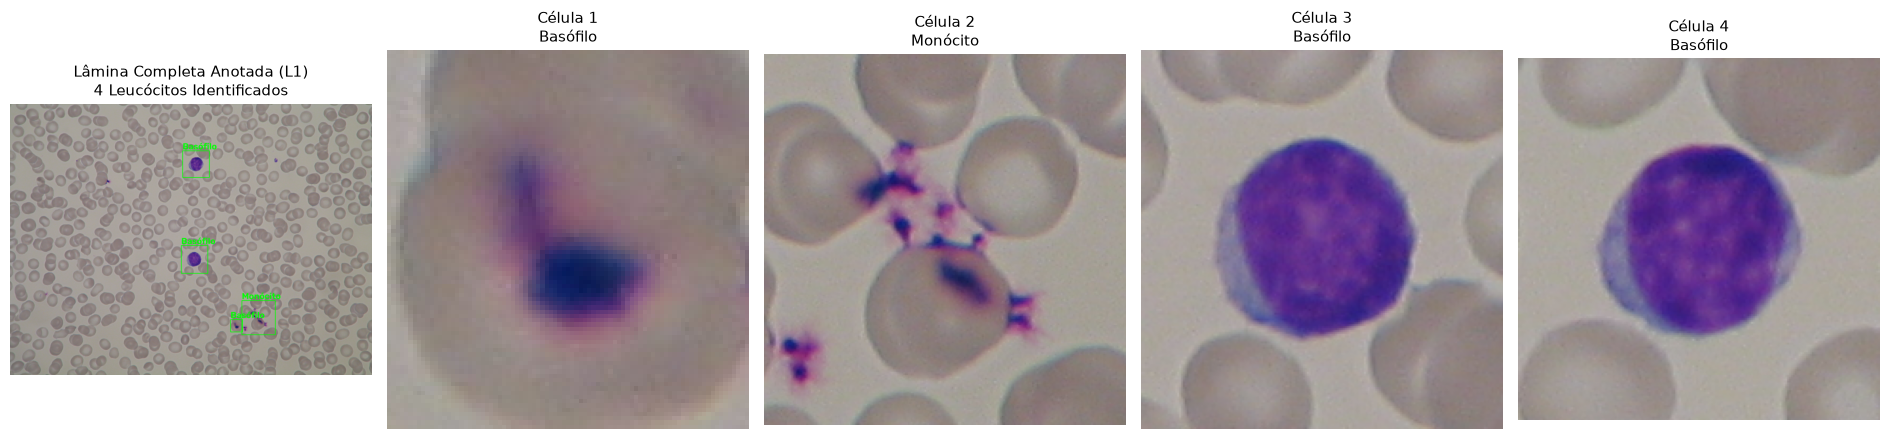

In [18]:
num_crops_exibir = min(4, len(crops_celulas))
if num_crops_exibir > 0:
    fig, eixos = plt.subplots(1, 1 + num_crops_exibir, figsize=(5 + 3.5 * num_crops_exibir, 6))
    eixos[0].imshow(lamina_anotada)
    eixos[0].set_title(f"Lâmina Completa Anotada ({SUBPASTA_LAMINA})\n{len(caixas)} Leucócitos Identificados", fontsize=11)
    eixos[0].axis("off")
    
    for idx in range(num_crops_exibir):
        eixos[idx + 1].imshow(crops_celulas[idx])
        eixos[idx + 1].set_title(f"Célula {idx + 1}\n{predicoes_lamina[idx]}", fontsize=11)
        eixos[idx + 1].axis("off")
else:
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(lamina_anotada)
    ax.set_title(f"Lâmina Completa Anotada ({SUBPASTA_LAMINA})", fontsize=12)
    ax.axis("off")

plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "auditoria_6_lamina_anotada.png", bbox_inches="tight", dpi=150)
plt.show()

### Emissão do Laudo de Leucograma Digital
Apresentação da contagem diferencial percentual com os intervalos de referência da prática médica.

        LAUDO DE CONTAGEM DIFERENCIAL DE LEUCÓCITOS (L1)
Total de Leucócitos Avaliados: 2
-----------------------------------------------------------------
  Linhagem  Contagem  Percentual (%) Valores de Referência
Neutrófilo         0             0.0             50% - 70%
 Linfócito         0             0.0             20% - 40%
  Monócito         0             0.0              2% - 10%
Eosinófilo         0             0.0               1% - 5%
  Basófilo         2           100.0               0% - 1%


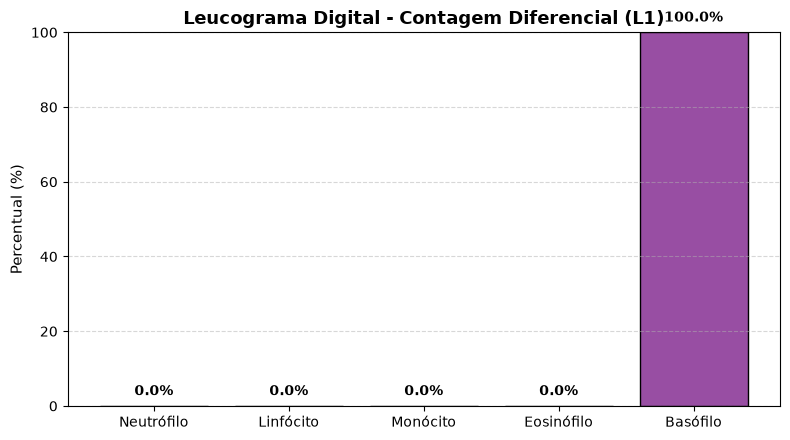

In [11]:
# Tabela de referência clínica normal no sangue periférico
referencias = {
    "Neutrófilo": "50% - 70%",
    "Linfócito": "20% - 40%",
    "Monócito": "2% - 10%",
    "Eosinófilo": "1% - 5%",
    "Basófilo": "0% - 1%"
}

df_laudo["Valores de Referência"] = df_laudo["Linhagem"].map(referencias)

print("=" * 65)
print(f"        LAUDO DE CONTAGEM DIFERENCIAL DE LEUCÓCITOS ({SUBPASTA_LAMINA})")
print("=" * 65)
print(f"Total de Leucócitos Avaliados: {total_contado}")
print("-" * 65)
print(df_laudo.to_string(index=False))
print("=" * 65)

# Gráfico do laudo hematológico
fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(df_laudo["Linhagem"], df_laudo["Percentual (%)"], color=["#4daf4a", "#377eb8", "#ff7f00", "#e41a1c", "#984ea3"], edgecolor="black")
ax.set_ylabel("Percentual (%)", fontsize=11)
ax.set_title(f"Leucograma Digital - Contagem Diferencial ({SUBPASTA_LAMINA})", fontsize=13, fontweight="bold")
ax.set_ylim(0, 100)

for barra in barras:
    yval = barra.get_height()
    ax.text(barra.get_x() + barra.get_width()/2.0, yval + 2, f"{yval:.1f}%", ha="center", va="bottom", fontweight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "auditoria_7_laudo_percentual.png", bbox_inches="tight", dpi=150)
plt.show()